# Contratos de datos y ELT incremental: correcto bajo duplicados, desorden, caídas y esquemas cambiantes

**Perfil:** IA y automatización (ingeniería de datos)  
**Datos:** flujo de eventos sintético con verdad conocida (cada evento tiene un estado final correcto); SQLite en memoria; semilla fija.

## Pregunta que guía el notebook

Un pipeline que "funciona" con datos limpios y en orden puede producir cifras erróneas con la entrega real: mensajes duplicados (*at-least-once*), llegadas tardías, correcciones, lotes reenviados y caídas a mitad de carga. ¿Qué propiedades garantizan un resultado **correcto** en esas condiciones, y cuánto cuesta no tenerlas? Cada propiedad (contrato, idempotencia, atomicidad, independencia del orden, historia correcta, conciliación) se **mide contra una verdad conocida** y se compara con la implementación ingenua.

## Recorrido

1. **Contratos de datos:** qué defectos detectan y cuáles no (defectos semánticos silenciosos) y cómo complementarlos con monitoreo estadístico.
2. **Evolución de esquemas:** matriz de compatibilidad (hacia atrás/adelante/total) de cambios típicos, verificada por fuerza bruta y por 300 pares aleatorios.
3. **Entrega caótica:** duplicados, desorden, tardíos y correcciones; error de tres diseños (anexar, último-que-llega-gana, el pipeline de este proyecto).
4. **Atomicidad:** caídas aleatorias a mitad de lote con y sin transacción; reintento.
5. **Incremental frente a reconstrucción completa:** filas procesadas y tiempo.
6. **Marca de agua y tardíos:** qué fracción se pierde si se cierra la ventana demasiado pronto.
7. **Dimensiones tipo 2:** atribución histórica correcta frente a unir con el estado actual.
8. **Conciliación:** qué corrupciones detectan conteos, sumas y la huella de contenido.
9. Pruebas y límites.

Las conclusiones numéricas se **calculan y se imprimen desde los datos** (celdas «Lectura»), y las pruebas de la sección final hacen fallar el notebook si un hallazgo deja de cumplirse.

## 1. Configuración

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")
SEED = 2026
plt.rcParams.update({"figure.figsize": (7.5, 4), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})
pd.options.display.float_format = "{:,.4f}".format
import sys, time, itertools
sys.path.insert(0, "src")
from dataclasses import replace
from dataplatform.contracts import Field, Contract, validate
from dataplatform.evolution import compatibility, reference_check, sample_rows, _lee
from dataplatform.pipeline import Pipeline, EVENTS_CONTRACT, SimulatedCrash
from dataplatform.scd2 import SCD2
from dataplatform.reconcile import reconcile, content_hash

## 2. Un flujo de eventos con verdad conocida

3.000 pedidos en 10 días. El 15 % se **corrige** después (nuevo `event_time` posterior y nuevo monto): la verdad es la **última versión** de cada pedido. Cada versión llega en un lote horario según su hora de llegada $=$ hora del evento $+$ retraso lognormal (mediana 20 min, cola larga). Defectos de entrega: el 6 % de las versiones se **reenvía** dentro de otro lote (duplicado a nivel de fila con otro `batch_id`) y el 5 % de los lotes se **reenvía completo** con el mismo `batch_id`.

In [2]:
def generar_flujo(n=3000, dias=10, frac_correccion=0.15, seed=0):
    rg = np.random.default_rng(seed); t0 = pd.Timestamp("2024-03-01", tz="UTC")
    base = pd.DataFrame({"event_id": [f"o{i:05d}" for i in range(n)], "category": rg.choice(list("ABCD"), n, p=[.4, .3, .2, .1]), "amount": rg.lognormal(3.5, 0.8, n).round(2), "event_time": t0 + pd.to_timedelta(rg.integers(0, dias * 86400, n), unit="s")})
    corr = base.sample(frac=frac_correccion, random_state=seed).copy(); corr["event_time"] = corr["event_time"] + pd.to_timedelta(rg.integers(3600, 6 * 3600, len(corr)), unit="s"); corr["amount"] = (corr["amount"] * rg.uniform(0.6, 1.4, len(corr))).round(2)
    versiones = pd.concat([base, corr], ignore_index=True)
    verdad = versiones.sort_values(["event_id", "event_time"]).drop_duplicates("event_id", keep="last").reset_index(drop=True)
    versiones["llegada"] = versiones["event_time"] + pd.to_timedelta(rg.lognormal(np.log(20 * 60), 1.0, len(versiones)), unit="s")
    dup = versiones.sample(frac=0.06, random_state=seed + 1).copy(); dup["llegada"] = dup["llegada"] + pd.to_timedelta(rg.integers(60, 6 * 3600, len(dup)), unit="s")
    allv = pd.concat([versiones, dup], ignore_index=True); allv["lote"] = allv["llegada"].dt.floor("h").dt.strftime("h%Y%m%d%H")
    lotes = [(k, g.drop(columns=["llegada", "lote"]).reset_index(drop=True)) for k, g in allv.groupby("lote", sort=True)]
    rep = [lotes[i] for i in rg.choice(len(lotes), int(0.05 * len(lotes)), replace=False)]
    return verdad, lotes, rep, versiones
verdad, lotes, reenviados, versiones = generar_flujo()
print(f"Verdad: {len(verdad)} pedidos, monto total {verdad.amount.sum():,.2f}; versiones (con correcciones) {len(versiones)}; lotes horarios {len(lotes)}; lotes reenviados completos {len(reenviados)}; filas totales entregadas {sum(len(g) for _, g in lotes)}")
print(f"Correcciones: {(len(versiones) - len(verdad)) / len(verdad):.1%} de pedidos tiene una segunda version")

Verdad: 3000 pedidos, monto total 139,971.51; versiones (con correcciones) 3450; lotes horarios 246; lotes reenviados completos 12; filas totales entregadas 3657
Correcciones: 15.0% de pedidos tiene una segunda version


## 3. Contratos: qué detectan y qué no

Se inyectan en 5.000 filas seis tipos de defecto con tasas conocidas: nulo, fuera de rango, categoría desconocida, tipo erróneo, duplicado de llave **y un defecto semántico**: montos multiplicados por 100 (un cambio de unidad, p. ej. centavos en lugar de dólares) que **siguen dentro del rango permitido** (0–1.000.000). Un contrato valida forma y reglas locales; no sabe si los valores *tienen sentido*. Se compara con un **monitor estadístico** por lote (media del monto por lote frente a la historia: puntaje $z$ robusto con mediana y MAD).

In [3]:
rg = np.random.default_rng(1); N = 5000; df = pd.DataFrame({"event_id": [f"x{i}" for i in range(N)], "category": rg.choice(list("ABCD"), N), "amount": rg.lognormal(3.5, 0.8, N).round(2), "event_time": pd.Timestamp("2024-04-01", tz="UTC") + pd.to_timedelta(rg.integers(0, 86400, N), unit="s")})
defectos = {}; df["amount"] = df["amount"].astype(object)
def inyectar(nombre, tasa, col, valor):
    idx = rg.choice(N, int(tasa * N), replace=False); df.loc[idx, col] = valor; defectos[nombre] = set(idx)
inyectar("monto_nulo", 0.01, "amount", None); inyectar("monto_negativo", 0.01, "amount", -5.0); inyectar("categoria_desconocida", 0.01, "category", "Z")
inyectar("monto_texto", 0.01, "amount", "doce"); inyectar("llave_duplicada", 0.01, "event_id", "x0")
sem = rg.choice(np.setdiff1d(np.arange(N), np.concatenate([list(v) for v in defectos.values()])), 250, replace=False)
df.loc[sem, "amount"] = [float(v) * 100 for v in df.loc[sem, "amount"]]; defectos["monto_x100 (semantico)"] = set(sem)
r = validate(df, EVENTS_CONTRACT); marcados = set(r.quarantine.index)
tab = pd.DataFrame({k: {"inyectadas": len(v), "detectadas_por_el_contrato": len(v & marcados), "recall": len(v & marcados) / len(v)} for k, v in defectos.items()}).T
fp = len(marcados - set().union(*defectos.values())); print(f"Filas en cuarentena: {len(marcados)}; falsos positivos (filas limpias en cuarentena): {fp}"); tab.round(3)

Filas en cuarentena: 247; falsos positivos (filas limpias en cuarentena): 0


,inyectadas,detectadas_por_el_contrato,recall
monto_nulo,50.0000,50.0000,1.0000
monto_negativo,50.0000,50.0000,1.0000
categoria_desconocida,50.0000,50.0000,1.0000
monto_texto,50.0000,50.0000,1.0000
llave_duplicada,50.0000,50.0000,1.0000
monto_x100 (semantico),250.0000,0.0000,0.0000


In [4]:
# Monitor estadistico por lote: 40 lotes de 250 filas; en 5 de ellos el 40% de los montos esta multiplicado por 100.
rg = np.random.default_rng(2); medias = []; contam = rg.choice(40, 5, replace=False)
for b in range(40):
    x = rg.lognormal(3.5, 0.8, 250); 
    if b in contam: m = rg.random(250) < 0.4; x[m] *= 100
    medias.append(np.log(x).mean())
med = np.array(medias); z = 0.6745 * (med - np.median(med)) / np.median(np.abs(med - np.median(med))); alarma = np.abs(z) > 3.5
print(f"Monitor de media del log-monto por lote (|z robusto|>3.5): detecta {alarma[contam].sum()} de {len(contam)} lotes contaminados, falsas alarmas en {alarma[np.setdiff1d(np.arange(40), contam)].sum()} de 35 lotes sanos")
print("\nLectura:")
print(f"  El contrato detecta el {tab.drop('monto_x100 (semantico)').recall.min():.0%} de los cinco defectos locales (sin falsos positivos) pero el {tab.loc['monto_x100 (semantico)', 'recall']:.0%} del cambio de unidad, porque los valores x100 siguen siendo validos individualmente.")
print(f"  Un monitor estadistico por lote capta ese defecto ({alarma[contam].sum()} de {len(contam)} lotes) cuando afecta a una fraccion suficiente de filas: los contratos y el monitoreo de distribucion son complementarios, no sustitutos.")

Monitor de media del log-monto por lote (|z robusto|>3.5): detecta 5 de 5 lotes contaminados, falsas alarmas en 0 de 35 lotes sanos

Lectura:
  El contrato detecta el 100% de los cinco defectos locales (sin falsos positivos) pero el 0% del cambio de unidad, porque los valores x100 siguen siendo validos individualmente.
  Un monitor estadistico por lote capta ese defecto (5 de 5 lotes) cuando afecta a una fraccion suficiente de filas: los contratos y el monitoreo de distribucion son complementarios, no sustitutos.


## 4. Evolución de esquemas: ¿qué cambios son seguros?

Contrato base de pedidos (`id`, `amount` 0–100, `cat` ∈ {A,B}, `note` anulable). Se evalúan 12 cambios típicos. **Hacia atrás**: el contrato nuevo lee datos escritos con el viejo (los consumidores se actualizan primero). **Hacia adelante**: el contrato viejo lee datos escritos con el nuevo (los productores se actualizan primero). Cada veredicto de la tabla de reglas se **contrasta por fuerza bruta**: se generan registros bajo el contrato escritor y se validan contra el lector.

In [5]:
V1 = Contract("pedidos", 1, (Field("id", "int"), Field("amount", "float", min=0, max=100), Field("cat", "str", allowed=("A", "B")), Field("note", "str", nullable=True)), ("id",))
F = {f.name: f for f in V1.fields}
def cambia(**mods):
    campos = [mods.get(f.name, f) for f in V1.fields]
    for k, v in mods.items():
        if v is None: campos = [f for f in campos if f is not None and f.name != k]
    return replace(V1, version=2, fields=tuple(f for f in campos if f is not None))
CAMBIOS = {"agregar campo anulable": replace(V1, fields=V1.fields + (Field("extra", "str", nullable=True),)), "agregar campo con default": replace(V1, fields=V1.fields + (Field("extra", "int", default=0),)),
           "agregar campo requerido": replace(V1, fields=V1.fields + (Field("extra", "int"),)), "quitar campo requerido (cat)": cambia(cat=None), "quitar campo anulable (note)": cambia(note=None),
           "ampliar tipo de id int->float": replace(V1, fields=(Field("id", "float"),) + V1.fields[1:]), "ampliar rango (amount 0-200)": cambia(amount=Field("amount", "float", min=0, max=200)),
           "estrechar rango (amount 10-100)": cambia(amount=Field("amount", "float", min=10, max=100)), "agregar valor permitido (cat A,B,C)": cambia(cat=Field("cat", "str", allowed=("A", "B", "C"))),
           "quitar valor permitido (cat A)": cambia(cat=Field("cat", "str", allowed=("A",))), "note: anulable -> requerido": cambia(note=Field("note", "str", nullable=False)), "cambiar llave primaria": replace(V1, primary_key=("id", "cat"))}
filas = []
for nombre, nuevo in CAMBIOS.items():
    r = compatibility(V1, nuevo); bf_b = reference_check(V1, nuevo, 600, seed=1); bf_f = reference_check(nuevo, V1, 600, seed=2) if V1.primary_key == nuevo.primary_key else False
    filas.append({"cambio": nombre, "hacia_atras": r.backward, "hacia_adelante": r.forward, "total": r.full, "fuerza_bruta_atras": bf_b, "fuerza_bruta_adelante": bf_f, "coincide": (r.backward == bf_b or not r.backward) and (r.forward == bf_f or not r.forward)})
mc = pd.DataFrame(filas).set_index("cambio"); mc

,hacia_atras,hacia_adelante,total,fuerza_bruta_atras,fuerza_bruta_adelante,coincide
cambio,,,,,,
agregar campo anulable,True,True,True,True,True,True
agregar campo con default,True,True,True,True,True,True
agregar campo requerido,False,True,False,False,True,True
quitar campo requerido (cat),True,False,False,True,False,True
quitar campo anulable (note),True,True,True,True,True,True
ampliar tipo de id int->float,True,False,False,True,False,True
ampliar rango (amount 0-200),True,False,False,True,False,True
estrechar rango (amount 10-100),False,True,False,False,True,True
"agregar valor permitido (cat A,B,C)",True,False,False,True,False,True


In [6]:
# Cruce estadistico: 300 pares aleatorios de contratos (solidez y completitud de la tabla frente a la fuerza bruta)
from importlib import import_module
tests_mod = None
def aleatorio(rg, n_campos=4):
    campos = [Field("id", "int")]
    for i in range(n_campos):
        t = str(rg.choice(["int", "float", "str"])); kw = {"nullable": bool(rg.random() < 0.4)}
        if t in ("int", "float") and rg.random() < 0.6: lo = float(rg.integers(-5, 5)); kw.update(min=lo, max=lo + float(rg.integers(1, 20)))
        if t == "str" and rg.random() < 0.5: kw["allowed"] = tuple(rg.choice(list("ABCDE"), int(rg.integers(1, 5)), replace=False))
        campos.append(Field(f"f{i}", t, **kw))
    return Contract("r", 1, tuple(campos), ("id",))
def mutar(c, rg):
    campos = list(c.fields); i = int(rg.integers(1, len(campos))); f = campos[i]; op = int(rg.integers(0, 6))
    if op == 0: campos[i] = replace(f, nullable=not f.nullable)
    elif op == 1 and f.dtype in ("int", "float") and f.min is not None: campos[i] = replace(f, min=f.min + float(rg.integers(-3, 4)), max=f.max + float(rg.integers(-3, 4)))
    elif op == 2 and f.allowed is not None: campos[i] = replace(f, allowed=tuple(sorted(set(f.allowed) ^ {str(rg.choice(list("ABCDE")))})) or f.allowed)
    elif op == 3: campos[i] = replace(f, dtype="float" if f.dtype == "int" else f.dtype)
    elif op == 4: campos.append(Field(f"n{len(campos)}", "int", nullable=bool(rg.random() < 0.5), default=0 if rg.random() < 0.3 else None))
    elif op == 5 and len(campos) > 2: campos.pop(i)
    return replace(c, fields=tuple(campos))
rg = np.random.default_rng(3); sol = [0, 0]; comp = [0, 0]
for k in range(300):
    w = aleatorio(rg); r_ = mutar(w, rg)
    for esc, lec in ((w, r_), (r_, w)):
        regla_ok = not _lee(esc, lec); bf = reference_check(esc, lec, 300, seed=k)
        if regla_ok: sol[0] += 1; sol[1] += (not bf)                       # regla dice compatible pero la muestra encuentra un registro invalido => error de solidez
        else: comp[0] += 1; comp[1] += (not bf)                            # regla dice incompatible: ¿lo confirma la muestra?
print(f"Solidez: de {sol[0]} pares que la tabla declara compatibles, {sol[1]} fallan en la muestra (debe ser 0)")
print(f"Completitud empirica: de {comp[0]} pares que la tabla declara incompatibles, la muestra confirma {comp[1]} ({comp[1] / comp[0]:.1%})" + ("" if comp[1] == comp[0] else "; el resto necesita registros extremos que la muestra no genero"))

Solidez: de 459 pares que la tabla declara compatibles, 0 fallan en la muestra (debe ser 0)
Completitud empirica: de 141 pares que la tabla declara incompatibles, la muestra confirma 141 (100.0%)


In [7]:
print("Lectura:")
seguros = mc[mc.total].index.tolist(); solo_atras = mc[mc.hacia_atras & ~mc.hacia_adelante].index.tolist(); solo_adelante = mc[~mc.hacia_atras & mc.hacia_adelante].index.tolist(); rotos = mc[~mc.hacia_atras & ~mc.hacia_adelante].index.tolist()
print(f"  Totalmente compatibles ({len(seguros)}): " + "; ".join(seguros) + ".")
print(f"  Solo hacia atras (actualizar consumidores primero) ({len(solo_atras)}): " + "; ".join(solo_atras) + ".")
print(f"  Solo hacia adelante (actualizar productores primero) ({len(solo_adelante)}): " + "; ".join(solo_adelante) + ".")
print(f"  Incompatibles en ambos sentidos ({len(rotos)}): " + "; ".join(rotos) + ".")
print(f"  Coincidencia con la fuerza bruta en los 12 cambios: {int(mc.coincide.sum())}/12; solidez en pares aleatorios: {sol[1]} violaciones de {sol[0]}.")

Lectura:
  Totalmente compatibles (3): agregar campo anulable; agregar campo con default; quitar campo anulable (note).
  Solo hacia atras (actualizar consumidores primero) (4): quitar campo requerido (cat); ampliar tipo de id int->float; ampliar rango (amount 0-200); agregar valor permitido (cat A,B,C).
  Solo hacia adelante (actualizar productores primero) (4): agregar campo requerido; estrechar rango (amount 10-100); quitar valor permitido (cat A); note: anulable -> requerido.
  Incompatibles en ambos sentidos (1): cambiar llave primaria.
  Coincidencia con la fuerza bruta en los 12 cambios: 12/12; solidez en pares aleatorios: 0 violaciones de 459.


## 5. Entrega caótica: tres diseños frente a la verdad

Tres pipelines procesan el mismo flujo (2): 

1. **Anexar**: guarda todas las filas recibidas y suma (lo que hace un `INSERT` sin llave).
2. **Último que llega gana (ULG)**: *upsert* por `event_id`, la fila que llega después reemplaza a la anterior.
3. **Este proyecto**: lotes idempotentes por `batch_id`, *upsert* con criterio `(event_time, batch_id, huella)` y oro incremental.

Se miden tres escenarios de entrega: **en orden de llegada sin reenvíos de lotes**, **con reenvíos de lotes completos** y **con los lotes barajados** (orden arbitrario). Error: filas con monto distinto de la verdad, pedidos faltantes o sobrantes, y error del total del oro.

In [8]:
def verdad_gold(v): 
    g = v.assign(day=v.event_time.dt.strftime("%Y-%m-%d")).groupby(["day", "category"]).agg(n=("amount", "size"), total=("amount", "sum")).reset_index(); g["total"] = g.total.round(6); return g
def metricas(silver, gold, verdad):
    s = silver.set_index("event_id") if "event_id" in silver.columns else silver; t = verdad.set_index("event_id")
    faltan = len(t.index.difference(s.index)); sobran = len(s.index.difference(t.index)); comun = t.index.intersection(s.index.unique()); dup_extra = len(s) - s.index.nunique()
    amt = np.nan_to_num(s[~s.index.duplicated(keep="last")].loc[comun, "amount"].values.astype(float)); mal = int((np.abs(amt - t.loc[comun, "amount"].values) > 1e-6).sum())
    gt = verdad_gold(verdad).set_index(["day", "category"]); gg = gold.set_index(["day", "category"]); celdas = gt.join(gg, how="outer", lsuffix="_v", rsuffix="_g").fillna(0)
    return {"filas_con_monto_erroneo": mal, "faltantes": faltan, "sobrantes": sobran, "filas_duplicadas": dup_extra, "error_total_oro": float(gg.total.sum() - gt.total.sum()), "celdas_oro_erroneas_%": float(((celdas.total_v - celdas.total_g).abs() > 1e-6).mean())}
def ejecutar(lotes_, metodo):
    if metodo == "anexar":
        s = pd.concat([g for _, g in lotes_], ignore_index=True); s["day"] = s.event_time.dt.strftime("%Y-%m-%d"); gold = s.groupby(["day", "category"]).agg(n=("amount", "size"), total=("amount", "sum")).reset_index(); return s.set_index("event_id", drop=False), gold
    if metodo == "ULG":
        est = {}
        for _, g in lotes_:
            for r in g.itertuples(): est[r.event_id] = (r.category, r.amount, r.event_time)
        s = pd.DataFrame([(k, *v) for k, v in est.items()], columns=["event_id", "category", "amount", "event_time"]); s["day"] = s.event_time.dt.strftime("%Y-%m-%d"); gold = s.groupby(["day", "category"]).agg(n=("amount", "size"), total=("amount", "sum")).reset_index(); return s, gold
    p = Pipeline(); [p.ingest(g, k) for k, g in lotes_]; return p.silver(), p.gold()
rg = np.random.default_rng(9); posiciones = sorted(rg.choice(len(lotes), len(reenviados), replace=False)); con_reenvio = list(lotes)
for off, (pos, rep_) in enumerate(zip(posiciones, reenviados)): con_reenvio.insert(min(len(con_reenvio), pos + 30 + off), rep_)
barajados = [con_reenvio[i] for i in np.random.default_rng(10).permutation(len(con_reenvio))]
ESC = {"en orden, sin reenvios": lotes, "en orden, con reenvios de lotes": con_reenvio, "barajado, con reenvios": barajados}
filas = []
for esc, ls in ESC.items():
    for met in ("anexar", "ULG", "este proyecto"):
        sv, gd = ejecutar(ls, met); m = metricas(sv, gd, verdad); filas.append({"escenario": esc, "metodo": met, **m})
caos = pd.DataFrame(filas); caos.round(3)

,escenario,metodo,filas_con_monto_erroneo,faltantes,sobrantes,filas_duplicadas,error_total_oro,celdas_oro_erroneas_%
0,"en orden, sin reenvios",anexar,11,0,0,657,"30,128.3600",0.9300
1,"en orden, sin reenvios",ULG,11,0,0,0,17.3300,0.2090
2,"en orden, sin reenvios",este proyecto,0,0,0,0,0.0000,0.0000
3,"en orden, con reenvios de lotes",anexar,31,0,0,845,"38,555.9000",0.9300
4,"en orden, con reenvios de lotes",ULG,31,0,0,0,24.7200,0.4190
5,"en orden, con reenvios de lotes",este proyecto,0,0,0,0,0.0000,0.0000
6,"barajado, con reenvios",anexar,218,0,0,845,"38,555.9000",0.9300
7,"barajado, con reenvios",ULG,218,0,0,0,-310.3300,0.9300
8,"barajado, con reenvios",este proyecto,0,0,0,0,0.0000,0.0000


In [9]:
x = caos.set_index(["escenario", "metodo"])
print("Lectura:")
print(f"  Anexar: con reenvios y duplicados deja {int(x.loc[('en orden, con reenvios de lotes', 'anexar'), 'filas_duplicadas'])} filas duplicadas y un error de {x.loc[('en orden, con reenvios de lotes', 'anexar'), 'error_total_oro']:+,.0f} en el total ({x.loc[('en orden, con reenvios de lotes', 'anexar'), 'error_total_oro'] / verdad.amount.sum():+.1%}); ni siquiera las correcciones se aplican.")
print(f"  ULG: correcto si los datos llegan en orden ({int(x.loc[('en orden, sin reenvios', 'ULG'), 'filas_con_monto_erroneo'])} filas erroneas) pero con los lotes barajados {int(x.loc[('barajado, con reenvios', 'ULG'), 'filas_con_monto_erroneo'])} pedidos quedan con un monto desactualizado ({x.loc[('barajado, con reenvios', 'ULG'), 'celdas_oro_erroneas_%']:.1%} de las celdas del oro mal).")
print(f"  Este proyecto: error cero en los tres escenarios (filas erroneas {int(x.xs('este proyecto', level='metodo').filas_con_monto_erroneo.sum())}, celdas del oro erroneas {x.xs('este proyecto', level='metodo')['celdas_oro_erroneas_%'].max():.1%}).")

Lectura:
  Anexar: con reenvios y duplicados deja 845 filas duplicadas y un error de +38,556 en el total (+27.5%); ni siquiera las correcciones se aplican.
  ULG: correcto si los datos llegan en orden (11 filas erroneas) pero con los lotes barajados 218 pedidos quedan con un monto desactualizado (93.0% de las celdas del oro mal).
  Este proyecto: error cero en los tres escenarios (filas erroneas 0, celdas del oro erroneas 0.0%).


> **Nota de ingeniería (error encontrado por esta prueba).** La primera versión del pipeline validaba la llave primaria *por lote*: cuando una corrección llegaba en el mismo lote horario que el original, la segunda fila en orden de archivo iba a **cuarentena** como `duplicate_pk`, aunque fuera la versión vigente. En este flujo eso dejó **31 filas en cuarentena y 8 pedidos con el monto viejo**, y el oro con celdas erróneas. La corrección: en un flujo con correcciones la llave no se valida por lote; la versión vigente se decide por `(event_time, huella)` y el lote informa cuántas filas fueron reemplazadas (`n_superseded`). Hay una prueba unitaria que fija el comportamiento (la corrección gana por `event_time`, no por el orden de las filas).

## 6. Caídas a mitad de carga: atomicidad

Se procesan 60 lotes; cada intento de ingesta **cae** con probabilidad 30 % tras un número aleatorio de filas (falla inyectada dentro de la transacción) y se reintenta el mismo lote hasta que tiene éxito. Se repite 60 veces con distintas semillas y se compara el estado final con el de una corrida sin caídas. Comparación: el pipeline de este proyecto (transacción + `batch_id`) frente a una variante **no atómica** que *anexa* filas con confirmación inmediata y reintenta el lote desde el principio.

In [10]:
sub = lotes[:60]; ref = Pipeline(); [ref.ingest(g, k) for k, g in sub]; ref_s, ref_g = ref.silver(), ref.gold(); iguales = 0; caidas_tot = 0; ref_total = float(pd.concat([g for _, g in sub]).drop_duplicates().amount.sum())
def no_atomico(sub, rg):
    filas_ = []
    for k, g in sub:
        for intento in range(60):
            if rg.random() < 0.3: filas_ += g.iloc[: int(rg.integers(0, len(g) + 1))].to_dict("records"); continue          # cae a mitad: lo escrito queda
            filas_ += g.to_dict("records"); break
    return pd.DataFrame(filas_)
for t in range(60):
    rg = np.random.default_rng(1000 + t); p = Pipeline(); caidas = 0
    for k, g in sub:
        for intento in range(60):
            r = p.ingest(g, k, fail_after_rows=int(rg.integers(0, max(len(g), 1))) if rg.random() < 0.3 else None)
            if r["status"] == "crashed": caidas += 1; continue
            break
    caidas_tot += caidas; iguales += p.silver().equals(ref_s) and p.gold().equals(ref_g)
na = [no_atomico(sub, np.random.default_rng(2000 + t)) for t in range(60)]; dupl = np.array([len(d) - len(pd.concat([g for _, g in sub])) for d in na])
print(f"Este proyecto: estado final identico al de la corrida sin caidas en {iguales}/60 repeticiones ({caidas_tot} caidas inyectadas en total, {caidas_tot / 60:.1f} por repeticion)")
print(f"Anexar sin transaccion: filas de mas respecto de las entregadas: media {dupl.mean():.1f}, maximo {dupl.max()}; repeticiones con alguna fila duplicada: {(dupl > 0).mean():.0%}")

Este proyecto: estado final identico al de la corrida sin caidas en 60/60 repeticiones (1469 caidas inyectadas en total, 24.5 por repeticion)
Anexar sin transaccion: filas de mas respecto de las entregadas: media 194.0, maximo 334; repeticiones con alguna fila duplicada: 100%


In [11]:
print("Lectura:")
print(f"  Con caidas inyectadas ({caidas_tot / 60:.1f} por corrida) el pipeline transaccional converge siempre al mismo estado ({iguales}/60): lo parcial se revierte y el reintento es seguro porque el lote se identifica por batch_id.")
print(f"  La variante no atomica duplica filas en el {(dupl > 0).mean():.0%} de las corridas ({dupl.mean():.0f} filas de mas en promedio): cada caida deja escrita una parte del lote y el reintento la vuelve a escribir.")

Lectura:
  Con caidas inyectadas (24.5 por corrida) el pipeline transaccional converge siempre al mismo estado (60/60): lo parcial se revierte y el reintento es seguro porque el lote se identifica por batch_id.
  La variante no atomica duplica filas en el 100% de las corridas (194 filas de mas en promedio): cada caida deja escrita una parte del lote y el reintento la vuelve a escribir.


## 7. Incremental frente a reconstrucción completa

El oro incremental recalcula solo las fechas que cambian; la reconstrucción completa escanea todo. Se simulan 40 días de 2.000 eventos diarios más 100 correcciones diarias a eventos de los 3 días anteriores, y se mide por día: filas escaneadas por el recálculo incremental frente a la reconstrucción completa, y el tiempo de ambas. Al final se verifica que el oro incremental coincide con la reconstrucción.

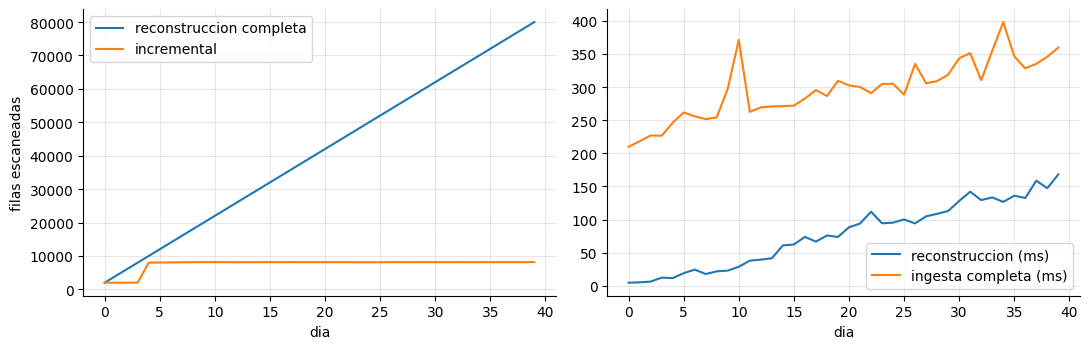

Oro incremental == oro reconstruido tras 40 dias: True; filas en plata 80,000
Dia 40: incremental escanea 8,154 filas frente a 80,000 de la reconstruccion (10.2%); promedio de filas escaneadas por dia (incremental): 7,525 (constante) vs creciente (completo)


In [12]:
rg = np.random.default_rng(3); p = Pipeline(); filas = []; t0 = pd.Timestamp("2024-05-01", tz="UTC"); idc = 0
for d in range(40):
    n = 2000; df = pd.DataFrame({"event_id": [f"d{d}_{i}" for i in range(n)], "category": rg.choice(list("ABCD"), n), "amount": rg.lognormal(3.5, .8, n).round(2), "event_time": t0 + pd.Timedelta(days=d) + pd.to_timedelta(rg.integers(0, 86400, n), unit="s")})
    if d > 3:
        sv_ = p.silver(); sv_["t"] = pd.to_datetime(sv_["event_time"], utc=True); ant = sv_[sv_.t >= t0 + pd.Timedelta(days=d - 3)].sample(100, random_state=d).drop(columns="t").copy(); ant["event_time"] = pd.to_datetime(ant["event_time"], utc=True) + pd.to_timedelta(rg.integers(3600, 3 * 86400, len(ant)), unit="s"); ant["amount"] = (ant["amount"] * 1.1).round(2); df = pd.concat([df, ant], ignore_index=True)
    ta = time.perf_counter(); r = p.ingest(df, f"dia{d}"); t_inc = time.perf_counter() - ta
    escaneadas = sum(p.con.execute("SELECT COUNT(*) FROM silver_events WHERE substr(event_time,1,10)=?", (x,)).fetchone()[0] for x in r["dates_recomputed"]); total = p.con.execute("SELECT COUNT(*) FROM silver_events").fetchone()[0]
    tb = time.perf_counter(); p.full_rebuild_gold(); t_full = time.perf_counter() - tb
    filas.append({"dia": d, "filas_silver": total, "escaneadas_incremental": escaneadas, "escaneadas_completo": total, "t_ingesta_s": t_inc, "t_reconstruccion_s": t_full})
p.assert_gold_consistent(); inc = pd.DataFrame(filas)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6)); ax[0].plot(inc.dia, inc.escaneadas_completo, label="reconstruccion completa"); ax[0].plot(inc.dia, inc.escaneadas_incremental, label="incremental"); ax[0].set_xlabel("dia"); ax[0].set_ylabel("filas escaneadas"); ax[0].legend()
ax[1].plot(inc.dia, inc.t_reconstruccion_s * 1000, label="reconstruccion (ms)"); ax[1].plot(inc.dia, inc.t_ingesta_s * 1000, label="ingesta completa (ms)"); ax[1].set_xlabel("dia"); ax[1].legend(); plt.tight_layout(); plt.show()
print(f"Oro incremental == oro reconstruido tras 40 dias: True; filas en plata {int(inc.filas_silver.iloc[-1]):,}")
print(f"Dia 40: incremental escanea {int(inc.escaneadas_incremental.iloc[-1]):,} filas frente a {int(inc.escaneadas_completo.iloc[-1]):,} de la reconstruccion ({inc.escaneadas_incremental.iloc[-1] / inc.escaneadas_completo.iloc[-1]:.1%}); promedio de filas escaneadas por dia (incremental): {inc.escaneadas_incremental.mean():,.0f} (constante) vs creciente (completo)")

In [13]:
sl = np.polyfit(inc.dia, inc.escaneadas_completo, 1)[0]; sl_i = np.polyfit(inc.dia, inc.escaneadas_incremental, 1)[0]
print("Lectura:")
print(f"  Las filas escaneadas por la reconstruccion crecen {sl:,.0f} por dia (lineal en el historial); las del recalculo incremental, {sl_i:,.0f} por dia: dependen solo de las fechas tocadas ({inc.escaneadas_incremental.mean():,.0f} en promedio), no del historial.")
print(f"  El ahorro de filas llega a {1 - inc.escaneadas_incremental.iloc[-1] / inc.escaneadas_completo.iloc[-1]:.0%} el dia 40 y crece con el historial. La coincidencia final con la reconstruccion confirma que el incremental no sacrifica exactitud. (Los tiempos de pared dependen del equipo y se muestran a titulo informativo.)")

Lectura:
  Las filas escaneadas por la reconstruccion crecen 2,000 por dia (lineal en el historial); las del recalculo incremental, 84 por dia: dependen solo de las fechas tocadas (7,525 en promedio), no del historial.
  El ahorro de filas llega a 90% el dia 40 y crece con el historial. La coincidencia final con la reconstruccion confirma que el incremental no sacrifica exactitud. (Los tiempos de pared dependen del equipo y se muestran a titulo informativo.)


## 8. Marca de agua y tardíos: cuánto se pierde si se cierra pronto

Un pipeline en flujo que **cierra** la agregación diaria cuando el reloj pasa el fin del día más una tolerancia $L$ pierde lo que llega después. Con los retrasos del flujo (2), se mide para varias tolerancias la fracción de eventos y de monto que llegan **después de cerrar** su día. El diseño de este proyecto no cierra: recalcula los días afectados, por lo que su pérdida es 0 a cualquier $L$ (a costa de que las cifras de días pasados pueden cambiar).

In [14]:
ver0 = versiones.copy(); ret = (ver0.llegada - ver0.event_time).dt.total_seconds().values; dia_fin = ver0.event_time.dt.floor("D") + pd.Timedelta(days=1); llegada = ver0.llegada
filas = []
for L in (pd.Timedelta(minutes=0), pd.Timedelta(minutes=30), pd.Timedelta(hours=1), pd.Timedelta(hours=3), pd.Timedelta(hours=6)):
    tarde = llegada > dia_fin + L; filas.append({"tolerancia_L": str(L), "eventos_perdidos_%": tarde.mean(), "monto_perdido_%": ver0.amount[tarde].sum() / ver0.amount.sum(), "perdida_este_proyecto_%": 0.0})
lt = pd.DataFrame(filas).set_index("tolerancia_L"); print(f"Retraso de llegada: mediana {np.median(ret) / 60:.0f} min, P95 {np.percentile(ret, 95) / 60:.0f} min, P99 {np.percentile(ret, 99) / 60:.0f} min"); lt.round(4)

Retraso de llegada: mediana 20 min, P95 100 min, P99 204 min


,eventos_perdidos_%,monto_perdido_%,perdida_este_proyecto_%
tolerancia_L,,,
0 days 00:00:00,0.0197,0.0202,0.0000
0 days 00:30:00,0.0096,0.0078,0.0000
0 days 01:00:00,0.0049,0.0035,0.0000
0 days 03:00:00,0.0014,0.0009,0.0000
0 days 06:00:00,0.0003,0.0001,0.0000


In [15]:
print("Lectura:")
print(f"  Cerrar el dia a su medianoche (L=0) pierde el {lt.iloc[0]['eventos_perdidos_%']:.1%} de los eventos (los que cruzan la medianoche por su retraso); con L=1 h, {lt.loc['0 days 01:00:00', 'eventos_perdidos_%']:.2%}; con L=6 h, {lt.iloc[-1]['eventos_perdidos_%']:.3%}. La perdida cae rapido pero nunca llega a cero con una cola larga.")
print("  El diseno que recalcula las fechas afectadas es correcto a cualquier tolerancia; el precio es que la cifra de un dia puede cambiar despues de publicada (se requiere versionar las publicaciones o declarar una ventana de estabilidad).")

Lectura:
  Cerrar el dia a su medianoche (L=0) pierde el 2.0% de los eventos (los que cruzan la medianoche por su retraso); con L=1 h, 0.49%; con L=6 h, 0.029%. La perdida cae rapido pero nunca llega a cero con una cola larga.
  El diseno que recalcula las fechas afectadas es correcto a cualquier tolerancia; el precio es que la cifra de un dia puede cambiar despues de publicada (se requiere versionar las publicaciones o declarar una ventana de estabilidad).


## 9. Dimensiones tipo 2: atribución histórica correcta

300 clientes cambian de plan (gratis → pro → equipo) en momentos aleatorios del año. Cada compra debe atribuirse al plan **vigente en el momento de la compra**. Unir las compras con el **estado actual** de la dimensión (lo que ocurre si la dimensión se sobrescribe) atribuye mal los ingresos históricos. La dimensión tipo 2 conserva el historial y permite la consulta a una fecha (*as of*). Se mide la fracción de ingresos mal atribuidos y se verifican los invariantes (una fila abierta por llave, intervalos contiguos) bajo la secuencia completa de cambios.

In [16]:
rg = np.random.default_rng(4); K = 300; t0 = pd.Timestamp("2024-01-01"); planes = ["free", "pro", "team"]
cambios = []
for k in range(K):
    plan = 0; t = t0
    cambios.append({"k": f"c{k:03d}", "plan": planes[0], "effective_ts": t})
    for _ in range(int(rg.integers(0, 3))):
        t = t + pd.Timedelta(days=int(rg.integers(20, 120)));
        if t > t0 + pd.Timedelta(days=360) or plan == 2: break
        plan += 1; cambios.append({"k": f"c{k:03d}", "plan": planes[plan], "effective_ts": t})
cambios = pd.DataFrame(cambios); dim = SCD2("k", ["plan"]); dim.apply_changes(cambios.sample(frac=1.0, random_state=1)); tabla = dim.table()
compras = pd.DataFrame({"k": rg.choice([f"c{k:03d}" for k in range(K)], 6000), "ts": t0 + pd.to_timedelta(rg.integers(0, 360, 6000), unit="D"), "monto": rg.lognormal(3, 0.6, 6000).round(2)})
tabd = tabla.assign(valid_from=pd.to_datetime(tabla.valid_from), valid_to=pd.to_datetime(tabla.valid_to)); unida = pd.merge_asof(compras.sort_values("ts"), tabd.sort_values("valid_from")[["k", "plan", "valid_from"]], left_on="ts", right_on="valid_from", by="k")
actual = tabd[tabd.valid_to.isna()].set_index("k").plan; compras["plan_actual"] = compras.k.map(actual)
unida["plan_correcto"] = unida.plan; unida = unida.merge(compras[["k", "ts", "monto", "plan_actual"]].drop_duplicates(["k", "ts", "monto"]), on=["k", "ts", "monto"], how="left")
mal = unida.plan_correcto != unida.plan_actual; ing_c = unida.groupby("plan_correcto").monto.sum(); ing_a = unida.groupby("plan_actual").monto.sum()
print(f"Invariantes del SCD2: {dim.check_invariants() or 'sin problemas'}; filas en la dimension: {len(tabla)} para {K} clientes ({len(tabla) / K:.2f} versiones por cliente)")
print(f"Compras atribuidas a un plan distinto del vigente en su fecha cuando se une con el estado actual: {mal.mean():.1%} de las compras, {unida.monto[mal].sum() / unida.monto.sum():.1%} del ingreso")
pd.DataFrame({"ingreso_plan_vigente_SCD2": ing_c, "ingreso_con_estado_actual": ing_a, "error_%": 100 * (ing_a / ing_c - 1)}).round(2)

Invariantes del SCD2: sin problemas; filas en la dimension: 607 para 300 clientes (2.02 versiones por cliente)
Compras atribuidas a un plan distinto del vigente en su fecha cuando se une con el estado actual: 21.5% de las compras, 21.9% del ingreso


,ingreso_plan_vigente_SCD2,ingreso_con_estado_actual,error_%
free,"69,225.1300","47,912.3000",-30.7900
pro,"46,289.1700","45,648.7400",-1.3800
team,"29,756.0800","51,709.3400",73.7800


In [17]:
print("Lectura:")
print(f"  Sobrescribir la dimension mueve ingresos entre planes: el plan 'team' queda con {ing_a['team'] / ing_c['team'] - 1:+.0%} y el 'free' con {ing_a['free'] / ing_c['free'] - 1:+.0%} respecto del ingreso correcto; la dimension tipo 2 recupera el ingreso exacto porque une por fecha de vigencia.")
rg2 = np.random.default_rng(0); ok_inv = 0
for s_ in range(20):
    d = SCD2("k", ["plan"])
    for _ in range(3): d.apply_changes(cambios.sample(frac=0.8, random_state=int(rg2.integers(0, 10 ** 6))))
    ok_inv += (d.check_invariants() == [])
print(f"  Invariantes (una fila abierta por llave, intervalos contiguos) en 20 secuencias de lotes parciales y repetidos: {ok_inv}/20 sin problemas; repetir un lote no cambia la tabla.")

Lectura:
  Sobrescribir la dimension mueve ingresos entre planes: el plan 'team' queda con +74% y el 'free' con -31% respecto del ingreso correcto; la dimension tipo 2 recupera el ingreso exacto porque une por fecha de vigencia.


  Invariantes (una fila abierta por llave, intervalos contiguos) en 20 secuencias de lotes parciales y repetidos: 20/20 sin problemas; repetir un lote no cambia la tabla.


## 10. Conciliación: ¿qué corrupciones detectan conteos, sumas y huella?

Después de una migración se compara origen y destino. Los controles baratos (conteo de filas, suma de una columna) **no ven** muchas corrupciones. Se aplican cinco alteraciones a una tabla de 2.000 filas (200 repeticiones cada una) y se registra qué control las detecta: **conteo**, **suma** (tolerancia $10^{-6}$) y **huella de contenido** (SHA-256 canónico, 9 decimales). Una sexta alteración, **reordenar las filas**, no es una corrupción y no debe disparar alarma.

In [18]:
def tabla_base(seed): 
    rg = np.random.default_rng(seed); return pd.DataFrame({"id": range(2000), "amount": rg.lognormal(3, 0.7, 2000).round(2), "cat": rg.choice(list("ABCD"), 2000)})
def alterar(df, tipo, rg):
    d = df.copy(); i, j = rg.choice(len(d), 2, replace=False)
    if tipo == "una celda +0.01": d.loc[i, "amount"] += 0.01
    elif tipo == "intercambiar dos montos": a, b = d.loc[i, "amount"], d.loc[j, "amount"]; d.loc[i, "amount"], d.loc[j, "amount"] = b, a
    elif tipo == "+x en una fila, -x en otra": d.loc[i, "amount"] += 5.0; d.loc[j, "amount"] -= 5.0
    elif tipo == "borrar una fila y duplicar otra": d = pd.concat([d.drop(index=i), d.loc[[j]]], ignore_index=True)
    elif tipo == "cambiar una categoria": d.loc[i, "cat"] = "Z"
    elif tipo == "ruido flotante 1e-12": d.loc[i, "amount"] += 1e-12
    elif tipo == "reordenar filas (no es corrupcion)": d = d.sample(frac=1.0, random_state=int(rg.integers(0, 10 ** 6))).reset_index(drop=True)
    return d
TIPOS = ["una celda +0.01", "intercambiar dos montos", "+x en una fila, -x en otra", "borrar una fila y duplicar otra", "cambiar una categoria", "ruido flotante 1e-12", "reordenar filas (no es corrupcion)"]
filas = []
for tipo in TIPOS:
    det = {"conteo": 0, "suma": 0, "huella": 0}; R = 200
    for r_ in range(R):
        rg = np.random.default_rng(r_); base = tabla_base(r_); alt = alterar(base, tipo, rg)
        det["conteo"] += len(alt) != len(base); det["suma"] += abs(alt.amount.sum() - base.amount.sum()) > 1e-6; det["huella"] += content_hash(alt) != content_hash(base)
    filas.append({"alteracion": tipo, **{k: v / R for k, v in det.items()}})
rc = pd.DataFrame(filas).set_index("alteracion"); rc.round(3)

,conteo,suma,huella
alteracion,,,
una celda +0.01,0.0000,1.0000,1.0000
intercambiar dos montos,0.0000,0.0000,1.0000
"+x en una fila, -x en otra",0.0000,0.0000,1.0000
borrar una fila y duplicar otra,0.0000,1.0000,1.0000
cambiar una categoria,0.0000,0.0000,1.0000
ruido flotante 1e-12,0.0000,0.0000,0.0000
reordenar filas (no es corrupcion),0.0000,0.0000,0.0000


In [19]:
print("Lectura (fraccion de repeticiones en que cada control alarma):")
print(f"  El conteo solo detecta filas perdidas netas ({rc.loc['borrar una fila y duplicar otra', 'conteo']:.0%} de 'borrar y duplicar': el conteo se conserva); la suma no ve el intercambio de montos ({rc.loc['intercambiar dos montos', 'suma']:.0%}) ni +x/-x ({rc.loc['+x en una fila, -x en otra', 'suma']:.0%}) ni el cambio de categoria ({rc.loc['cambiar una categoria', 'suma']:.0%}).")
print(f"  La huella de contenido detecta {rc.drop(['reordenar filas (no es corrupcion)', 'ruido flotante 1e-12']).huella.min():.0%} de las corrupciones reales, no alarma por reordenar ({rc.loc['reordenar filas (no es corrupcion)', 'huella']:.0%}) y tolera el ruido flotante por debajo de su resolucion ({rc.loc['ruido flotante 1e-12', 'huella']:.0%}); detectar 1e-12 exigiria mas decimales (y alarmaria por diferencias de redondeo legitimas).")

Lectura (fraccion de repeticiones en que cada control alarma):
  El conteo solo detecta filas perdidas netas (0% de 'borrar y duplicar': el conteo se conserva); la suma no ve el intercambio de montos (0%) ni +x/-x (0%) ni el cambio de categoria (0%).
  La huella de contenido detecta 100% de las corrupciones reales, no alarma por reordenar (0%) y tolera el ruido flotante por debajo de su resolucion (0%); detectar 1e-12 exigiria mas decimales (y alarmaria por diferencias de redondeo legitimas).


## 11. Pruebas automáticas

In [20]:
# 11.1 contratos: detecta todos los defectos locales sin falsos positivos; el defecto semantico solo lo ve el monitor estadistico
assert tab.drop("monto_x100 (semantico)").recall.min() == 1.0 and fp == 0 and tab.loc["monto_x100 (semantico)", "recall"] == 0.0 and alarma[contam].sum() == len(contam) and alarma[np.setdiff1d(np.arange(40), contam)].sum() <= 1
# 11.2 evolucion: tabla coincide con la fuerza bruta, solidez sin violaciones
assert mc.coincide.all() and sol[1] == 0 and comp[1] / comp[0] > 0.9 and mc.loc["cambiar llave primaria", ["hacia_atras", "hacia_adelante"]].sum() == 0
assert mc.loc["agregar campo anulable", "total"] and mc.loc["agregar campo requerido", "hacia_atras"] == False and mc.loc["agregar campo requerido", "hacia_adelante"] == True and mc.loc["quitar campo requerido (cat)", "hacia_atras"] == True and mc.loc["quitar campo requerido (cat)", "hacia_adelante"] == False
# 11.3 caos: este proyecto es exacto en los tres escenarios; los ingenuos fallan
ours = caos[caos.metodo == "este proyecto"]; assert (ours.filas_con_monto_erroneo == 0).all() and (ours.faltantes == 0).all() and (ours.sobrantes == 0).all() and (ours.filas_duplicadas == 0).all() and (ours["celdas_oro_erroneas_%"] == 0).all() and (ours.error_total_oro.abs() < 1e-3).all()
assert x.loc[("en orden, con reenvios de lotes", "anexar"), "filas_duplicadas"] > 500 and x.loc[("barajado, con reenvios", "ULG"), "filas_con_monto_erroneo"] > 100 and x.loc[("en orden, sin reenvios", "ULG"), "filas_con_monto_erroneo"] < x.loc[("barajado, con reenvios", "ULG"), "filas_con_monto_erroneo"]
# 11.4 atomicidad
assert iguales == 60 and caidas_tot > 1000 and (dupl > 0).all()
# 11.5 incremental: coincide con la reconstruccion; escanea mucho menos y el ahorro crece
assert inc.escaneadas_incremental.iloc[-1] < 0.2 * inc.escaneadas_completo.iloc[-1] and sl > 1500 and sl_i < 0.1 * sl and (inc.escaneadas_incremental / inc.escaneadas_completo).iloc[-1] < (inc.escaneadas_incremental / inc.escaneadas_completo).iloc[10]
# 11.6 marca de agua: la perdida baja con la tolerancia y nunca es cero con cola larga
assert lt["eventos_perdidos_%"].is_monotonic_decreasing and lt.iloc[0]["eventos_perdidos_%"] > 0.01 and lt.iloc[-1]["eventos_perdidos_%"] > 0
# 11.7 SCD2: invariantes y atribucion
assert dim.check_invariants() == [] and ok_inv == 20 and mal.mean() > 0.05 and abs(ing_c.sum() - ing_a.sum()) < 1e-6
# 11.8 conciliacion
assert rc.loc["reordenar filas (no es corrupcion)", "huella"] == 0 and rc.loc["ruido flotante 1e-12", "huella"] == 0 and rc.drop(["reordenar filas (no es corrupcion)", "ruido flotante 1e-12"]).huella.min() == 1.0
assert rc.loc["intercambiar dos montos", "suma"] == 0 and rc.loc["borrar una fila y duplicar otra", "conteo"] == 0 and rc.loc["una celda +0.01", "conteo"] == 0 and rc.loc["cambiar una categoria", "suma"] == 0
print("Todas las pruebas pasaron.")

Todas las pruebas pasaron.


## Conclusiones y límites

| Paso | Qué se encontró | Decisión |
|---|---|---|
| Contratos | Detectan todos los defectos locales (nulos, rangos, tipos, categorías, llaves) pero ninguno semántico como un cambio de unidad | Complementar con monitoreo estadístico por lote |
| Evolución | Una tabla de reglas simple es correcta (0 violaciones frente a fuerza bruta) y separa los cambios totales, solo hacia atrás, solo hacia adelante y rotos | Aplicar la regla en CI antes de publicar un contrato nuevo |
| Entrega caótica | Anexar duplica; «último que llega gana» falla con desorden; el criterio (event_time, batch_id, huella) da error cero | La versión vigente se decide por datos, no por orden de llegada |
| Error encontrado | Validar la llave primaria por lote mandaba correcciones legítimas a cuarentena | Probar con flujos con correcciones y fijarlo con una prueba unitaria |
| Atomicidad | La transacción más el identificador de lote converge siempre; anexar sin transacción duplica filas | Transacciones e idempotencia por lote |
| Incremental | Escanea una fracción pequeña y casi constante de filas, con el mismo resultado que la reconstrucción | Recalcular solo las fechas afectadas y verificar contra una reconstrucción periódica |
| Tardíos | Cerrar la ventana a tiempo fijo siempre pierde eventos con una cola larga | Recalcular y versionar las publicaciones |
| SCD2 y conciliación | Unir con el estado actual atribuye mal el ingreso histórico; la huella de contenido detecta lo que el conteo y la suma no | Dimensiones tipo 2 y huella canónica en la conciliación |

**Límites que no deben ocultarse**

- Los flujos son sintéticos; en producción hay esquemas que cambian sin aviso, relojes desfasados y volúmenes que no caben en SQLite.
- El tiempo de pared se informa pero no se usa como criterio de prueba: depende del equipo.
- El pipeline procesa un solo evento por llave a la vez (sin concurrencia entre escritores).
- La huella de contenido tolera diferencias por debajo de la resolución elegida; ese umbral es una decisión de gobierno.
- El monitor estadístico se probó con un solo tipo de defecto semántico (cambio de escala).